# Анализ BCR после обработки MiXCR

Образец `DChu_T7_pbmc_d7COVID2_2`, парные FASTQ из `BCR_homework.zip`. Выполнены проверка FASTQ, обработка MiXCR 4.7.0 с UMI и анализ полученных клонотипов через `repseq` 0.1.3.

Ноутбук адаптирован по `UCB_seminar.ipynb`: здесь анализируются иммуноглобулиновые цепи BCR. Treg, CD4 и CD8 из другого архива относятся к TCR и рассматриваются в `UCB_homework.ipynb`. Единственный BCR-образец не используется как дополнительная TCR-реплика.

## Данные и параметры

Для повторного запуска положите `BCR_homework.zip` рядом с ноутбуком либо задайте `BCR_RAW_DIR`. Для пересборки из FASTQ нужны MiXCR 4.7.0 и лицензия. Путь к `mixcr.jar` задаётся в `MIXCR_JAR`, путь к лицензии в `MI_LICENSE_FILE`. Ключа в ноутбуке и архиве нет. При наличии готового экспорта повторная upstream обработка пропускается.

Выбран пресет `milab-human-rna-ig-umi-multiplex`, вид Homo sapiens, встроенная библиотека `repseqio.v5.1`, два потока. Он использует BCR-ориентированный kAligner2, извлечение и коррекцию UMI. Это обоснованное рабочее предположение о лабораторном протоколе: ядро адаптера соответствует структуре чтений, но отдельное описание подготовки библиотеки в архиве отсутствует. Оценка корректности настройки опирается также на отчёты выравнивания, UMI и сборки. Структура UMI следует официальному пресету, её нельзя считать независимо подтверждённой одним совпадением адаптера.

Сборка выполняется по CDR3 с разделением по V, J и C. В основном downstream анализе варианты с одинаковыми CDR3nt+V+J объединяются по C, чтобы смена изотипа не создавала отдельный CDR3-клонотип. Для изотипного состава и проверки влияния определения клонотипа сохраняется исходный экспорт с разделением по C. Анализ полных последовательностей и SHM-деревьев в это задание не входит.

In [1]:
from pathlib import Path
import os, json, zipfile, subprocess, shutil, collections, gzip, hashlib
import importlib.resources
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import gammaln
from repseq import io as rsio, stats, clone_filter as clf
from repseq.common_functions import get_column_names_from_clonoset
stats.AA_PROPS_PATH = str(importlib.resources.files('repseq') / 'resourses' / 'aa_property_table.txt')
sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
OUT = Path('results/bcr')
OUT.mkdir(parents=True, exist_ok=True)
Path('figures').mkdir(exist_ok=True)
SAMPLE = 'DChu_T7_pbmc_d7COVID2_2'
def find_raw():
    for p in [Path(os.environ.get('BCR_RAW_DIR', 'data/bcr_raw')), Path('../../work/raw')]:
        if (p / (SAMPLE + '_R1.fastq.gz')).is_file():
            return p.resolve()
    for p in [Path('BCR_homework.zip'), Path('../BCR_homework.zip'), Path('/home/euegene/Downloads/Telegram Desktop/BCR_homework.zip')]:
        if p.is_file():
            with zipfile.ZipFile(p) as z:
                z.extractall('work/bcr_raw')
            return Path('work/bcr_raw').resolve()
    raise FileNotFoundError('Нужны BCR_homework.zip или BCR_RAW_DIR')
RAW = find_raw()
files = [RAW / (SAMPLE + f'_R{i}.fastq.gz') for i in [1, 2]]
print([p.name for p in files])

['DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz', 'DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz']


## Качество FASTQ

Проверяются все записи FASTQ: ID в парах, длины, неизвестные основания и качество Phred+33. Профиль после ядра адаптера показан для первых 100 тысяч пар. Сырые 14-меры после адаптера используются только как техническое описание, а не как готовое число молекул.

In [2]:
quality = [np.zeros(94, dtype=np.int64), np.zeros(94, dtype=np.int64)]
lengths = [collections.Counter(), collections.Counter()]
base_n, base_count, adapter_positions = [0, 0], [0, 0], collections.Counter()
adapter = b'TGGTATCAACGCAGAGT'
umi_profile = np.zeros((24, 5), dtype=np.int64)
sample_umis = collections.Counter()
count = 0
with gzip.open(files[0], 'rb') as a, gzip.open(files[1], 'rb') as b:
    while True:
        batch_q = [[], []]
        done = False
        for i in range(10000):
            headers = [a.readline(), b.readline()]
            if not headers[0] or not headers[1]:
                assert headers[0] == headers[1], 'Read counts differ'
                done = True
                break
            assert headers[0].startswith(b'@') and headers[1].startswith(b'@')
            assert headers[0].split()[0] == headers[1].split()[0], 'Paired read IDs differ'
            for read, f in enumerate([a, b]):
                seq, plus, qual = f.readline().strip(), f.readline().strip(), f.readline().strip()
                assert plus.startswith(b'+') and len(seq) == len(qual) and len(seq) > 0
                lengths[read][len(seq)] += 1
                base_n[read] += seq.count(b'N')
                base_count[read] += len(seq)
                batch_q[read].append(qual)
                if read == 0:
                    position = seq.find(adapter)
                    adapter_positions[position] += 1
                    if count < 100000 and 0 <= position <= 2:
                        after = seq[position + len(adapter):position + len(adapter) + 24]
                        for j, base in enumerate(after):
                            umi_profile[j, b'ACGT'.find(bytes([base])) if base in b'ACGT' else 4] += 1
                        sample_umis[after[:14].decode()] += 1
            count += 1
        for read in [0, 1]:
            scores = np.frombuffer(b''.join(batch_q[read]), dtype=np.uint8).astype(np.int16) - 33
            if len(scores):
                assert scores.min() >= 0 and scores.max() < 94
                quality[read] += np.bincount(scores, minlength=94)
        if done:
            break
        if count % 200000 == 0:
            print('pairs', count, flush=True)
qc = {'read_pairs': count, 'read_id_pairs_match': True, 'fastq_records_valid': True,
      'adapter_R1_exact_positions': dict(adapter_positions),
      'adapter_R1_position_0_to_2_fraction': sum(adapter_positions[i] for i in [0, 1, 2]) / count,
      'UMI14_unique_first_100000_reads_with_exact_adapter': len(sample_umis),
      'UMI14_records_first_100000_reads_with_exact_adapter': sum(sample_umis.values()),
      'reads': []}
for i in [0, 1]:
    qc['reads'].append({'filename': files[i].name, 'length_counts': dict(lengths[i]),
                        'bases': base_count[i], 'N_fraction': base_n[i] / base_count[i],
                        'mean_phred': float(np.dot(np.arange(94), quality[i]) / quality[i].sum()),
                        'Q20_fraction': float(quality[i][20:].sum() / quality[i].sum()),
                        'Q30_fraction': float(quality[i][30:].sum() / quality[i].sum()),
                        'sha256': hashlib.file_digest(open(files[i], 'rb'), 'sha256').hexdigest()})
(OUT / 'raw_qc.json').write_text(json.dumps(qc, indent=2))
np.savez(OUT / 'raw_qc_histograms.npz', quality=np.array(quality), umi_profile=umi_profile)
display(pd.DataFrame(qc['reads'])[['filename', 'mean_phred', 'Q20_fraction', 'Q30_fraction', 'N_fraction']].round(5))
print('Число пар:', qc['read_pairs'])
print('Точное ядро адаптера в позиции 0, 1 или 2:', round(qc['adapter_R1_position_0_to_2_fraction'] * 100, 2), '%')

pairs 200000


pairs 400000


pairs 600000


pairs 800000


,filename,mean_phred,Q20_fraction,Q30_fraction,N_fraction
0,DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz,34.95270,0.92952,0.89113,0.0000
1,DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz,31.94006,0.81796,0.74851,0.0003


Число пар: 938889
Точное ядро адаптера в позиции 0, 1 или 2: 95.84 %


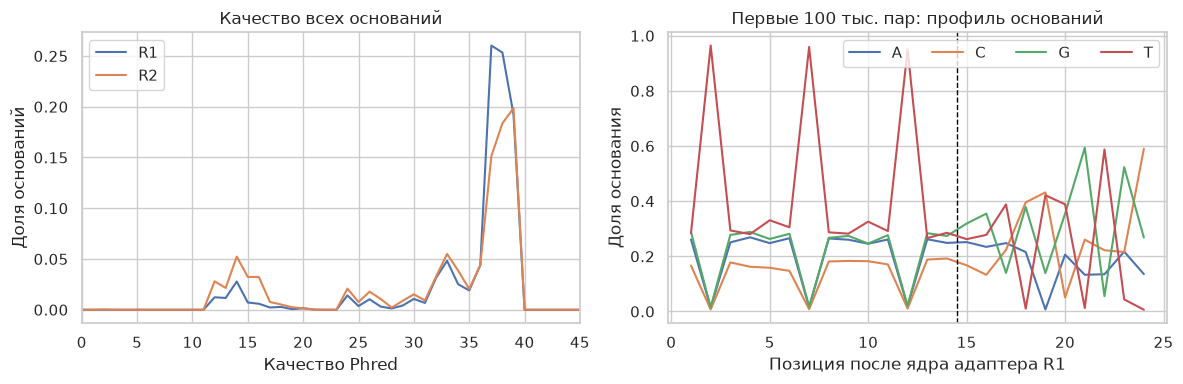

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i in [0, 1]:
    axes[0].plot(np.arange(94), quality[i] / quality[i].sum(), label=f'R{i + 1}')
axes[0].set(xlim=(0, 45), xlabel='Качество Phred', ylabel='Доля оснований', title='Качество всех оснований')
axes[0].legend()
profile = umi_profile / umi_profile.sum(axis=1, keepdims=True)
for i, base in enumerate('ACGT'):
    axes[1].plot(np.arange(1, 25), profile[:, i], label=base)
axes[1].axvline(14.5, color='black', ls='--', lw=1)
axes[1].set(xlabel='Позиция после ядра адаптера R1', ylabel='Доля основания', title='Первые 100 тыс. пар: профиль оснований')
axes[1].legend(loc='upper right', ncol=4)
fig.tight_layout(); fig.savefig('figures/bcr_raw_qc.png', dpi=150, bbox_inches='tight'); plt.show(); plt.close(fig)

В архиве **938 889 пар**, все чтения длиной 251 основание. Записи корректны, ID в парах совпадают. Q30 составляет **89,11% в R1** и **74,85% в R2**, поэтому для R2 особенно важны коррекция ошибок и проверка потерь на downstream этапах.

Точное ядро адаптера `TGGTATCAACGCAGAGT` найдено в позиции 0, 1 или 2 у **95,84% R1**. Фактическая доля распознанных тегов ниже определяется MiXCR, который допускает предусмотренные пресетом несовпадения. Число различных сырых UMI не равно числу клеток или готовых консенсусов.

## Обработка MiXCR

Пайплайн: `align`, `refineTagsAndSort`, `assemble`, `exportClones`. Из FASTQ извлекаются UMI, корректируются ошибки тегов, фильтруются группы и строятся консенсусы. Клонотипы экспортируются с молекулярными и read-счётчиками. Промежуточные выравнивания сохраняются в `work`, отчёты и конечные таблицы в `results/bcr/`.

In [4]:
jar_candidates = [Path(os.environ.get('MIXCR_JAR', 'mixcr.jar')), Path('../../work/tools/mixcr.jar')]
jar = next((p.resolve() for p in jar_candidates if p.is_file()), None)
mixcr = ['java', '-Xmx1200m', '-jar', str(jar)] if jar is not None else (['mixcr'] if shutil.which('mixcr') else None)
MIXCR_WORK = RAW.parent / 'bcr_mixcr'
MIXCR_WORK.mkdir(exist_ok=True)
prefix = MIXCR_WORK / SAMPLE
command = None if mixcr is None else mixcr + [
    'analyze', 'milab-human-rna-ig-umi-multiplex', '--threads', '2',
    '--assemble-clonotypes-by', 'CDR3', '--split-clones-by', 'V',
    '--split-clones-by', 'J', '--split-clones-by', 'C',
    str(files[0]), str(files[1]), str(prefix)]
clone_paths = sorted(OUT.glob(SAMPLE + '*.clones_*.tsv'))
if not clone_paths:
    work_clones = sorted(MIXCR_WORK.glob(SAMPLE + '*.clones_*.tsv'))
    if not work_clones:
        assert command is not None, 'Установите MiXCR 4.7.0 и задайте MIXCR_JAR'
        process = subprocess.run(command + ['--force-overwrite'], capture_output=True, text=True)
        (MIXCR_WORK / 'execution.log').write_text(process.stdout + process.stderr)
        assert process.returncode == 0, 'MiXCR не завершил обработку: проверьте execution.log'
        (MIXCR_WORK / 'command.json').write_text(json.dumps(command, indent=2))
        work_clones = sorted(MIXCR_WORK.glob(SAMPLE + '*.clones_*.tsv'))
    assert work_clones, 'Не найден конечный экспорт клонотипов'
    for p in MIXCR_WORK.iterdir():
        if p.name.startswith(SAMPLE) and (p.name.endswith(('.report.txt', '.report.json', '.clns', '.qc.json', '.qc.txt')) or p in work_clones):
            shutil.copy2(p, OUT / p.name)
    for source, destination in [('execution.log', 'mixcr_execution.log'), ('command.json', 'command.json'), ('run_status.json', 'upstream_run_status.json')]:
        if (MIXCR_WORK / source).is_file():
            shutil.copy2(MIXCR_WORK / source, OUT / destination)
    effective_preset = MIXCR_WORK.parent / 'bcr_preset.yaml'
    if effective_preset.is_file():
        shutil.copy2(effective_preset, OUT / 'effective_preset.yaml')
    clone_paths = sorted(OUT.glob(SAMPLE + '*.clones_*.tsv'))
assert clone_paths
(OUT / 'status.json').write_text(json.dumps({'state': 'upstream_finished', 'exit_code': 0, 'mixcr_version': '4.7.0'}, indent=2))
print('Экспортированные цепи:', [p.name for p in clone_paths])
print('Отчёты:', [p.name for p in sorted(OUT.glob('*.report.txt'))])

Экспортированные цепи: ['DChu_T7_pbmc_d7COVID2_2.clones_IGH.tsv']
Отчёты: ['DChu_T7_pbmc_d7COVID2_2.align.report.txt', 'DChu_T7_pbmc_d7COVID2_2.assemble.report.txt', 'DChu_T7_pbmc_d7COVID2_2.refine.report.txt']


,stage,read_pairs,fraction_of_raw
0,Исходные FASTQ,938889,1.00000
1,Успешно выровнены,865681,0.92203
2,После фильтрации UMI,782678,0.83362
3,Использованы в клонотипах,764915,0.81470


,stage,UMI_groups
0,До коррекции,175450
1,После коррекции,163191
2,После фильтрации,103842


,step,check,status,value
5,refineTagsAndSort,Reads dropped in tags error correction and fil...,WARN,9.59%
8,refineTagsAndSort,Reads dropped in tags filtering,WARN,9.59%
10,assemble,Barcode collisions in clonotype assembly,WARN,3.59%


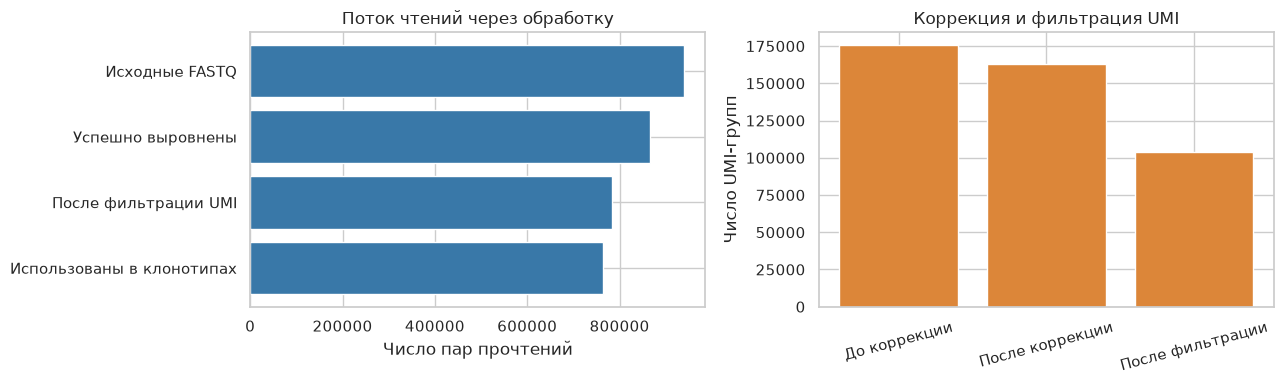

In [5]:
reports = {p.name: json.loads(p.read_text()) for p in sorted(OUT.glob('*.report.json'))}
alignment = next(v for k, v in reports.items() if k.endswith('.align.report.json'))
refinement = next(v for k, v in reports.items() if k.endswith('.refine.report.json'))
assembly = next(v for k, v in reports.items() if k.endswith('.assemble.report.json'))
correction = refinement['correctionReport']
umi_step = correction['steps'][0]
group_filter = correction['filterReport']
assert alignment['totalReadsProcessed'] == qc['read_pairs']
read_flow = pd.DataFrame([
    {'stage': 'Исходные FASTQ', 'read_pairs': qc['read_pairs']},
    {'stage': 'Успешно выровнены', 'read_pairs': alignment['aligned']},
    {'stage': 'После фильтрации UMI', 'read_pairs': correction['outputRecords']},
    {'stage': 'Использованы в клонотипах', 'read_pairs': assembly['readsInClones']}])
read_flow['fraction_of_raw'] = read_flow.read_pairs / qc['read_pairs']
read_flow.to_csv(OUT / 'upstream_summary.csv', index=False)
umi_flow = pd.DataFrame([
    {'stage': 'До коррекции', 'UMI_groups': umi_step['inputDiversity']},
    {'stage': 'После коррекции', 'UMI_groups': umi_step['outputDiversity']},
    {'stage': 'После фильтрации', 'UMI_groups': group_filter['numberOfGroupsAccepted']}])
umi_flow.to_csv(OUT / 'UMI_group_summary.csv', index=False)
qc_checks = json.loads(next(OUT.glob(SAMPLE + '*.qc.json')).read_text())
qc_table = pd.DataFrame([{'step': c['step'], 'check': c['check']['label'],
                          'status': c['status'], 'value': c['payload']['printedValue']}
                         for c in qc_checks])
qc_table.to_csv(OUT / 'mixcr_qc_checks.csv', index=False)
display(read_flow.round(5))
display(umi_flow)
display(qc_table.loc[qc_table.status != 'OK'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(read_flow.stage.iloc[::-1], read_flow.read_pairs.iloc[::-1], color='#3978a8')
axes[0].set(xlabel='Число пар прочтений', title='Поток чтений через обработку')
axes[1].bar(umi_flow.stage, umi_flow.UMI_groups, color='#dc8639')
axes[1].set(ylabel='Число UMI-групп', title='Коррекция и фильтрация UMI')
axes[1].tick_params(axis='x', rotation=15)
fig.tight_layout(); fig.savefig('figures/bcr_upstream_QC.png', dpi=150, bbox_inches='tight'); plt.show(); plt.close(fig)

### Интерпретация обработки MiXCR

UMI распознаны у **935 789 из 938 889 пар (99,67%)**. Успешно выровнена **865 681 пара (92,20%)**. Все успешно выровненные рецепторные последовательности аннотированы как IGH. Это репертуар тяжёлой цепи BCR. Отсутствие IGK/IGL в результате не означает отсутствия лёгких цепей в клетках.

Коррекция сократила число различных UMI с **175 450 до 163 191**. После фильтрации осталось **103 842 UMI-группы** и **782 678 пар**. Эффективный порог составил три прочтения на группу. В итоговые клонотипы вошло **764 915 пар**, то есть **81,47% исходных FASTQ**. Значение **97,73%** в отчёте сборки имеет другой знаменатель: это доля от входа этапа assemble после UMI-фильтрации.

Получено **42 865 вариантов CDR3nt+V+J+C**, из них **1235 (2,88%)** имеют непродуктивную CDR3. Непродуктивная часть составляет **1,31% суммы молекулярных счётчиков**. Продуктивность здесь определяется по CDR3 и не означает функциональную проверку всего антитела.

**Предупреждения QC сохранены.** MiXCR пометил множественные консенсусы у **3,59% групп** как возможные коллизии баркодов. При фильтрации тегов исключено **9,59% выровненных чтений**. Это технические ограничения, поэтому сумма молекулярных счётчиков клонотипов не трактуется как точное число независимых исходных молекул или клеток. Одной UMI-группе может соответствовать несколько консенсусов. Высокие доли распознанных тегов, выровненных и перекрывающихся чтений поддерживают выбор пресета, но не заменяют отсутствующий лабораторный протокол.

## Функциональные клонотипы и определения

Сначала проверяется состав цепей. Для каждой таблицы рассчитываются `clonoset_stats`, для IGH оставляются продуктивные CDR3. Частоты определяются по отдельному UMI-счётчику (`by_umi=True`), а не по readCount.

Основная единица анализа: CDR3nt+V+J с объединением по C. Альтернативная единица: CDR3nt+V+J+C из исходной сборки. CDR3-клонотип BCR не равен B-клеточной линии: соматические гипермутации могут менять CDR3 у потомков одной клетки. Число UMI отражает молекулярные наблюдения РНК после обработки, а не число B-клеток.

In [6]:
def pooled_cdr3(table):
    keys = ['cdr3nt', 'cdr3aa', 'v', 'j']
    pooled = table.groupby(keys, as_index=False, dropna=False)['count'].sum()
    pooled['count'] = pooled['count'].astype('int64')
    pooled['freq'] = pooled['count'] / pooled['count'].sum()
    assert pooled['count'].sum() == table['count'].sum()
    return pooled.sort_values('count', ascending=False).reset_index(drop=True)


def expected_richness(counts, depth):
    counts = np.asarray(counts, dtype=np.int64)
    values, multiplicity = np.unique(counts, return_counts=True)
    total = int(counts.sum())
    if depth == total:
        return float(len(counts))
    log_denominator = gammaln(total + 1) - gammaln(depth + 1) - gammaln(total - depth + 1)
    available = total - values
    missed = np.zeros(len(values))
    ok = available >= depth
    missed[ok] = np.exp(np.minimum(0, gammaln(available[ok] + 1) - gammaln(depth + 1)
                                   - gammaln(available[ok] - depth + 1) - log_denominator))
    return float(np.sum(multiplicity * (1 - missed)))


def take_molecules(table, depth, seed):
    counts = table['count'].to_numpy(dtype=np.int64)
    draw = np.random.default_rng(seed).multivariate_hypergeometric(counts, depth)
    selected = table.loc[draw > 0].copy()
    selected['count'] = draw[draw > 0]
    selected['freq'] = selected['count'] / depth
    assert selected['count'].sum() == depth
    return selected.reset_index(drop=True)


def clone_metrics(table):
    result = stats.calculate_diversity_stats_cl(table)
    result.update(stats.calculate_convergence_cl(table))
    result.update({'molecular_observations': int(table['count'].sum()),
                   'top1_fraction': float(table['freq'].max()),
                   'top10_fraction': float(table['freq'].nlargest(10).sum()),
                   'top100_fraction': float(table['freq'].nlargest(100).sum()),
                   'mean_cdr3aa_len': float(np.average(table.cdr3aa.str.len(), weights=table['count']))})
    return result


def isotype_class(gene):
    if pd.isna(gene) or gene == '':
        return 'Unassigned'
    if str(gene).startswith('IGHGP'):
        return 'Unassigned'
    for prefix, label in [('IGHM', 'IgM'), ('IGHD', 'IgD'), ('IGHG', 'IgG'), ('IGHA', 'IgA'), ('IGHE', 'IgE')]:
        if str(gene).startswith(prefix):
            return label
    return 'Unassigned'


def analyze_bcr(clone_paths):
    tables, chain_rows = {}, []
    for path in clone_paths:
        chain = path.stem.split('_')[-1]
        raw = rsio.read_clonoset(path)
        if raw.empty:
            continue
        columns = get_column_names_from_clonoset(raw)
        assert columns['umi'], 'В экспорте отсутствует отдельный молекулярный счётчик'
        qc_row = stats.calculate_clonoset_stats_cl(raw)
        chain_rows.append({'chain': chain, **qc_row})
        tables[chain] = raw
    chain_qc = pd.DataFrame(chain_rows)
    chain_qc.to_csv(OUT / 'chain_qc.csv', index=False)
    assert 'IGH' in tables, 'Не получен клоносет IGH'
    variants = clf.Filter(functionality='f', by_umi=True).apply(tables['IGH'])
    variants = variants.loc[variants.v.str.startswith('IGH', na=False)].copy()
    variants['freq'] = variants['count'] / variants['count'].sum()
    assert len(variants) > 0 and variants['count'].gt(0).all()
    main = pooled_cdr3(variants)
    variants.to_csv(OUT / 'IGH_functional_VJC.tsv', sep='\t', index=False)
    main.to_csv(OUT / 'IGH_functional_pooled_C.tsv', sep='\t', index=False)

    definitions = pd.DataFrame([{'definition': 'CDR3nt+V+J+C', **clone_metrics(variants)},
                                {'definition': 'CDR3nt+V+J', **clone_metrics(main)}])
    definitions.to_csv(OUT / 'IGH_metrics_by_definition.csv', index=False)
    properties = stats.calculate_cdr3_properties_cl(variants)
    pd.DataFrame([properties]).to_csv(OUT / 'IGH_cdr3_properties.csv', index=False)

    total = int(main['count'].sum())
    depths = np.unique(np.r_[np.geomspace(10, total, 35).astype(int), min(5000, total), min(10000, total), total])
    rarefaction = pd.DataFrame([{'depth': int(n), 'expected_richness': expected_richness(main['count'], int(n))}
                                for n in depths])
    assert np.isclose(rarefaction.iloc[-1].expected_richness, len(main))
    assert np.all(np.diff(rarefaction.expected_richness) >= -1e-5)
    rarefaction.to_csv(OUT / 'IGH_rarefaction.csv', index=False)

    primary_depth = min(10000, total)
    sensitivity = []
    for depth in sorted({primary_depth // 2, primary_depth, total}):
        for seed in [100, 101, 102]:
            sampled = take_molecules(main, depth, seed)
            sensitivity.append({'depth': depth, 'seed': seed, **clone_metrics(sampled)})
    sensitivity = pd.DataFrame(sensitivity)
    sensitivity.to_csv(OUT / 'IGH_depth_sensitivity.csv', index=False)

    read_table = clf.Filter(functionality='f', by_umi=False).apply(tables['IGH'])
    read_table = read_table.loc[read_table.v.str.startswith('IGH', na=False)].copy()
    read_table['isotype'] = read_table.c.map(isotype_class)
    variants['isotype'] = variants.c.map(isotype_class)
    molecules = variants.groupby('isotype', dropna=False)['count'].sum().rename('molecules')
    reads = read_table.groupby('isotype', dropna=False)['count'].sum().rename('read_pairs')
    isotypes = pd.concat([molecules, reads], axis=1).fillna(0)
    isotypes['molecule_fraction'] = isotypes.molecules / isotypes.molecules.sum()
    isotypes['read_fraction'] = isotypes.read_pairs / isotypes.read_pairs.sum()
    isotypes.to_csv(OUT / 'IGH_isotypes.csv')
    constant_genes = variants.groupby('c', dropna=False)['count'].sum().rename('molecules').to_frame()
    constant_genes['fraction'] = constant_genes.molecules / constant_genes.molecules.sum()
    constant_genes.to_csv(OUT / 'IGH_constant_genes.csv')
    usage = pd.concat([main.groupby(segment)['freq'].sum().rename('fraction').reset_index().rename(columns={segment: 'gene'}).assign(segment=segment)
                       for segment in ['v', 'j']], ignore_index=True)
    usage.to_csv(OUT / 'IGH_VJ_usage.csv', index=False)
    return {'chain_qc': chain_qc, 'variants': variants, 'main': main, 'definitions': definitions,
            'properties': properties, 'rarefaction': rarefaction, 'sensitivity': sensitivity,
            'isotypes': isotypes, 'usage': usage}


def show_bcr_figure(fig, name):
    fig.tight_layout()
    fig.savefig(Path('figures') / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_sequence_and_genes(result):
    main = result['main']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1.2, 1.2, 1]})
    lengths = main.assign(length=main.cdr3aa.str.len()).groupby('length')['freq'].sum()
    axes[0].bar(lengths.index, lengths, color='#3978a8')
    axes[0].set(xlabel='Длина CDR3, аминокислоты', ylabel='Доля молекулярных наблюдений', title='IGH: длины CDR3')
    for segment, ax in [('v', axes[1]), ('j', axes[2])]:
        values = main.groupby(segment)['freq'].sum().nlargest(15).sort_values()
        values.plot.barh(ax=ax, color='#3978a8')
        ax.set(xlabel='Доля молекулярных наблюдений', ylabel='Ген', title=f'IGH: {segment.upper()} usage')
    show_bcr_figure(fig, 'bcr_IGH_sequences_genes')


def plot_isotypes(result):
    table = result['isotypes'].reindex(['IgM', 'IgD', 'IgG', 'IgA', 'IgE', 'Unassigned']).dropna(how='all')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    table[['molecule_fraction', 'read_fraction']].rename(columns={'molecule_fraction': 'Молекулы (UMI)', 'read_fraction': 'Пары прочтений'}).plot.bar(ax=axes[0], color=['#3978a8', '#e89438'])
    axes[0].set(xlabel='Класс иммуноглобулина', ylabel='Доля', title='Изотипы: частоты по UMI и чтениям')
    axes[0].tick_params(axis='x', rotation=30)
    genes = result['variants'].groupby('c')['count'].sum().sort_values()
    (genes / genes.sum()).plot.barh(ax=axes[1], color='#3978a8')
    axes[1].set(xlabel='Доля молекулярных наблюдений', ylabel='Лучший C-ген', title='Константные гены IGH')
    show_bcr_figure(fig, 'bcr_IGH_isotypes')


def plot_clonal_structure(result):
    frequencies = result['main']['freq'].sort_values(ascending=False).to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ranks = np.arange(1, len(frequencies) + 1)
    axes[0].plot(ranks, frequencies, color='#3978a8')
    axes[0].set(xscale='log', yscale='log', xlabel='Ранг клонотипа', ylabel='Доля молекулярных наблюдений', title='Ранг и частота CDR3nt+V+J')
    axes[1].plot(ranks, np.cumsum(frequencies), color='#3978a8')
    axes[1].set(xscale='log', xlabel='Число крупнейших клонотипов', ylabel='Суммарная доля молекул', title='Концентрация частот')
    show_bcr_figure(fig, 'bcr_IGH_clonal_structure')


def plot_bcr_rarefaction(result):
    curve = result['rarefaction']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax in axes:
        ax.plot(curve.depth, curve.expected_richness, color='#3978a8')
        ax.set(xlabel='Глубина, молекулярные наблюдения', ylabel='Ожидаемое число клонотипов')
    axes[1].set_xscale('log')
    axes[0].set_title('Точная гипергеометрическая rarefaction')
    axes[1].set_title('Те же данные: логарифмическая шкала')
    show_bcr_figure(fig, 'bcr_IGH_rarefaction')


def plot_bcr_sensitivity(result):
    table = result['sensitivity']
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    for ax, (column, label) in zip(axes, [('diversity', 'Число клонотипов'), ('shannon_wiener', 'Shannon, натуральный логарифм'), ('clonality', 'Клональность: 1 - H / ln(S)')]):
        mean = table.groupby('depth')[column].mean()
        sd = table.groupby('depth')[column].std()
        ax.errorbar(mean.index, mean, yerr=sd, marker='o', color='#3978a8', capsize=4)
        ax.set(xlabel='Глубина, молекулярные наблюдения', ylabel=label)
    fig.suptitle('Чувствительность к глубине: среднее и SD трёх субсэмплов')
    show_bcr_figure(fig, 'bcr_IGH_depth_sensitivity')

In [7]:
result = analyze_bcr(clone_paths)
display(result['chain_qc'][['chain', 'clones', 'clones_func', 'reads', 'reads_func', 'umi', 'umi_func']])
metric_columns = ['definition', 'molecular_observations', 'diversity', 'shannon_wiener', 'clonality', 'inverse_simpson', 'convergence', 'top10_fraction', 'mean_cdr3aa_len']
display(result['definitions'][metric_columns].round(5))
display(pd.DataFrame([result['properties']])[['mean_cdr3nt_len', 'mean_insert_size', 'zero_insert_freq', 'cdr3_5_charge', 'cdr3_5_hydropathy']].round(5))

,chain,clones,clones_func,reads,reads_func,umi,umi_func
0,IGH,42865,41630,764915,755321,104172,102809


,definition,molecular_observations,diversity,shannon_wiener,clonality,inverse_simpson,convergence,top10_fraction,mean_cdr3aa_len
0,CDR3nt+V+J+C,102809,41630,9.35245,0.12073,1365.91833,1.00897,0.05259,18.1517
1,CDR3nt+V+J,102809,34292,9.19422,0.11955,1166.60688,1.00897,0.05892,18.1517


,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,cdr3_5_charge,cdr3_5_hydropathy
0,54.4551,13.04127,0.0104,-0.08928,-1.03144


## Длина CDR3 и использование V/J

Доли взвешены молекулярными наблюдениями. Для V показаны 15 наиболее используемых генов, для J все доступные гены. Выбирается лучший hit без аллеля, как в исходном семинарском ноутбуке. Неоднозначность аннотации не моделируется.

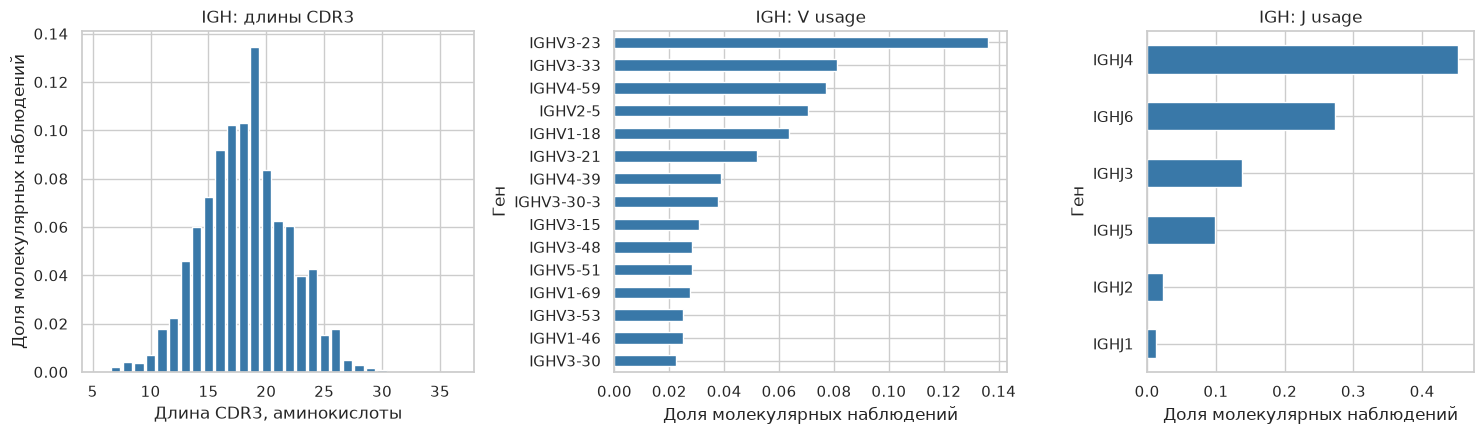

In [8]:
plot_sequence_and_genes(result)

## Изотипный состав

Исходные варианты, разделённые по C, используются для оценки классов иммуноглобулинов. IgG1-4 объединены в IgG, IgA1-2 в IgA. Неопределённые C и попадания на псевдоген IGHGP отнесены к Unassigned. Доли по readCount и UMI приведены отдельно: различие показывает влияние размера групп амплифицированных чтений. Это относительный состав транскриптов в обработанной библиотеке, а не доля клеток в крови.

,molecules,read_pairs,molecule_fraction,read_fraction
isotype,,,,
IgA,14089,97851,0.13704,0.12955
IgD,22726,174364,0.22105,0.23085
IgG,23548,168573,0.22905,0.22318
IgM,42410,314208,0.41251,0.41599
Unassigned,36,325,0.00035,0.00043


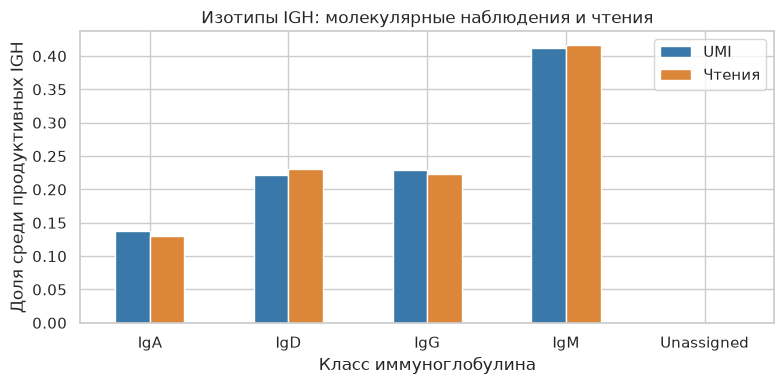

In [9]:
display(result['isotypes'].round(5))
fig, ax = plt.subplots(figsize=(8, 4))
result['isotypes'][['molecule_fraction', 'read_fraction']].plot.bar(ax=ax, color=['#3978a8', '#dc8639'])
ax.set(xlabel='Класс иммуноглобулина', ylabel='Доля среди продуктивных IGH', title='Изотипы IGH: молекулярные наблюдения и чтения')
ax.tick_params(axis='x', rotation=0)
ax.legend(['UMI', 'Чтения'])
show_bcr_figure(fig, 'bcr_IGH_isotypes')

## Альфа-разнообразие и концентрация частот

Richness показывает число обнаруженных CDR3nt+V+J-клонотипов. Shannon учитывает их частоты, клональность равна 1 − H/ln(S), inverse Simpson равен 1/Σp². По оси X ниже клонотипы отсортированы от наиболее частых к редким. По оси Y справа суммарная доля молекул в крупнейших клонотипах.

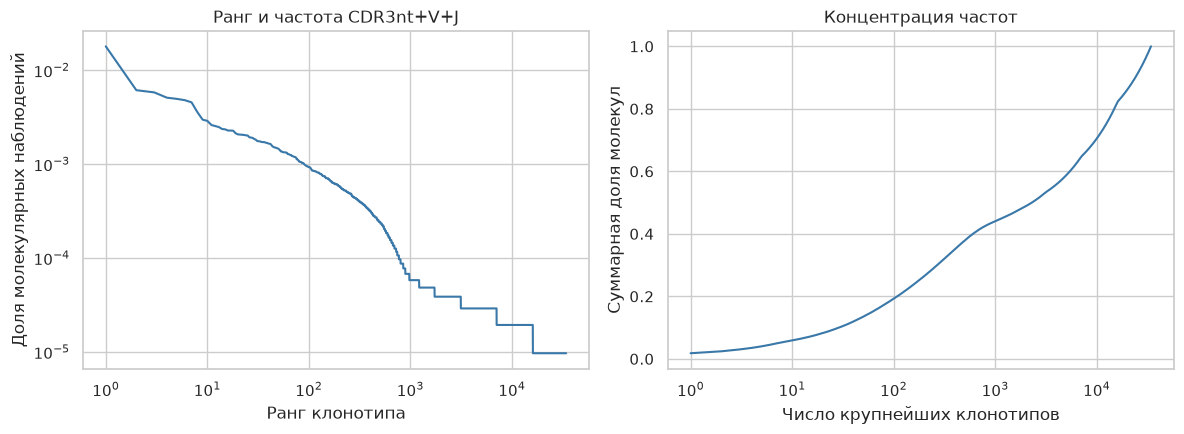

In [10]:
plot_clonal_structure(result)

## Конвергенция

Показано отношение числа уникальных CDR3nt к CDR3aa и варианты с дополнительным совпадением V либо V+J. В BCR оно может отражать как независимые перестройки, так и соматические изменения внутри одной линии. Само повышение конвергенции не доказывает общий антиген или независимое возникновение похожих B-клеточных линий.

In [11]:
display(result['definitions'][['definition', 'convergence', 'convergence_v', 'convergence_vj']].round(5))

,definition,convergence,convergence_v,convergence_vj
0,CDR3nt+V+J+C,1.00897,1.0086,1.00859
1,CDR3nt+V+J,1.00897,1.0086,1.00859


## Rarefaction

Точное ожидание числа клонотипов при выборке без возвращения: E[S(m)] = Σᵢ[1 − C(N−nᵢ,m)/C(N,m)]. N задаёт число молекулярных наблюдений, nᵢ их число для клонотипа. Кривая относится к наблюдаемой библиотеке и не оценивает полноту репертуара всего организма.

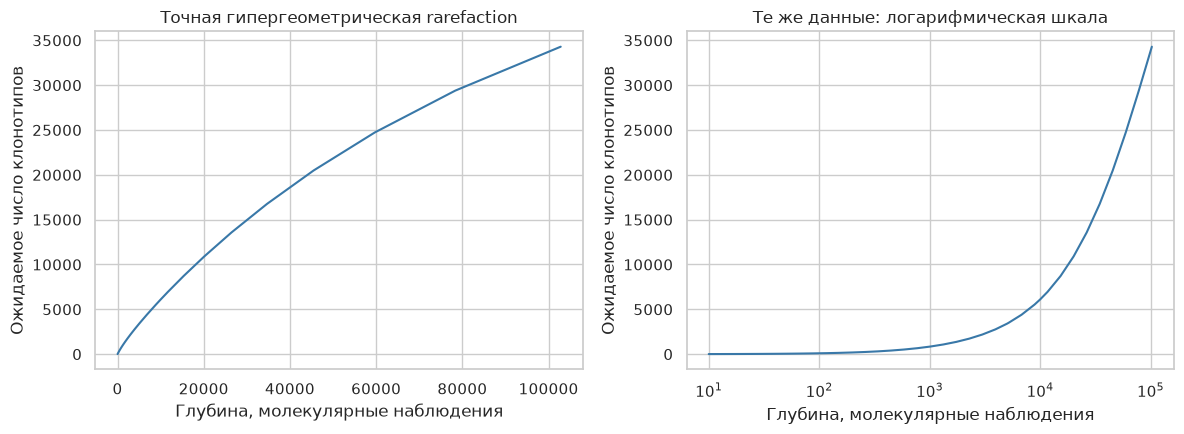

In [12]:
plot_bcr_rarefaction(result)

## Чувствительность к глубине

Сравниваются две стандартные глубины и полная функциональная библиотека. На каждой глубине выполнены три субсэмпла без возвращения с seed 100, 101, 102. На графиках показаны среднее и стандартное отклонение этих трёх технических повторов. Это не доверительные интервалы между людьми и не три биологических образца.

,diversity,shannon_wiener,clonality,top10_fraction
depth,,,,
5000,3369.66667,7.75516,0.04523,0.05953
10000,6072.00000,8.17263,0.06185,0.05863
102809,34292.00000,9.19422,0.11955,0.05892


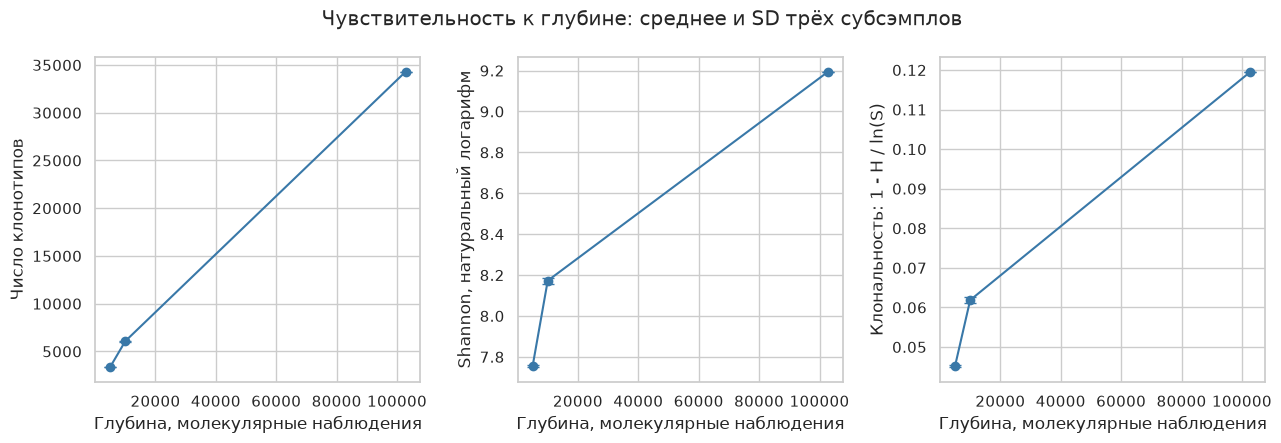

In [13]:
display(result['sensitivity'].groupby('depth')[['diversity', 'shannon_wiener', 'clonality', 'top10_fraction']].mean().round(5))
plot_bcr_sensitivity(result)

## Интерпретация BCR

**Определение клонотипа.** После фильтрации осталось **41 630 продуктивных вариантов CDR3nt+V+J+C**, сумма их молекулярных счётчиков **102 809**. Объединение одинаковых CDR3nt+V+J по C уменьшает число операционных клонотипов до **34 292** при сохранении суммы счётчиков. Разница в 7338 вариантов показывает, что часть одинаковых CDR3nt+V+J наблюдается с разными C. Такое объединение полезно для анализа CDR3, но само по себе не доказывает происхождение последовательностей от одной B-клеточной линии.

**CDR3 и сегменты.** Средняя длина CDR3 с весами молекулярных счётчиков составляет **18,15 аминокислоты**, наиболее частая длина **19**. Оценка средней длины вставок по V/D/J-аннотации равна **13,04 нт**, доля наблюдений без вставок **1,04%**. Эта оценка зависит от разметки сегментов и не является числом соматических мутаций. Чаще всего используется **IGHV3-23 (13,61%)**, затем IGHV3-33 (8,12%) и IGHV4-59 (7,70%). Среди J преобладают **IGHJ4 (45,27%)** и **IGHJ6 (27,27%)**. Профиль характеризует данную обработанную библиотеку и может зависеть от биологии и праймеров.

**Изотипы.** Среди продуктивных IGH молекулярные доли составляют **IgM 41,25%, IgD 22,11%, IgG 22,90%, IgA 13,70%**. Около **0,04%** отнесено к неопределённым C, включая одно попадание на IGHGP. Присутствуют транскрипты непереключённых и переключённых классов иммуноглобулинов. Доли описывают транскрипты после обработки. Они не равны долям B-клеток и не позволяют установить причину иммунного ответа.

**Альфа-разнообразие.** Для основного определения CDR3nt+V+J богатство равно **34 292**, Shannon **9,194**, клональность **0,1196**, inverse Simpson **1166,6**. Частоты распределены неравномерно: самый частый клонотип содержит **1,80%**, десять крупнейших **5,89%**, сто крупнейших **19,24%** молекулярных наблюдений. Эти показатели описывают концентрацию частот без вывода о её причине.

**Конвергенция.** Отношение числа уникальных CDR3nt к CDR3aa равно **1,00897**, а с дополнительным требованием совпадения V+J **1,00859**. При данном определении сильного объединения разных нуклеотидных CDR3 в одинаковые аминокислотные последовательности нет. Значение около 1 не свидетельствует об отсутствии SHM: мутации вне CDR3 в этом анализе не измерялись.

**Rarefaction и глубина.** Кривая продолжает расти. Среди объединённых клонотипов **18 202** представлены одним молекулярным наблюдением. При глубине **5000** среднее богатство трёх субсэмплов **3370**, при **10 000** оно равно **6072**. Shannon увеличивается с **7,755 до 8,173**, клональность с **0,0452 до 0,0619**. Поэтому абсолютные индексы зависят от глубины. При этом доля десяти крупнейших клонотипов остаётся около **5,9%** на обеих глубинах и в полной библиотеке: оценка концентрации наиболее частых клонотипов устойчивее в этой проверке. Кривые описывают наблюдаемую библиотеку, без оценки полноты BCR-репертуара всего организма.

Получен описательный профиль одного BCR-образца. Клинических и межгрупповых выводов этот дизайн не поддерживает.

## Ограничения

В данных один bulk-образец. Сравнивать клинические группы, делать осмысленные межобразцовые F2/MDS и проверять возрастные или клинические гипотезы здесь нельзя. Такие блоки исходного TCR-ноутбука не применяются к единственному BCR-образцу.

Название файла содержит `d7COVID2`, но подтверждённых клинических метаданных и контроля нет. Ни изотипы, ни частые CDR3 не устанавливают антигенную специфичность или связь с COVID. В отсутствие клеточных баркодов также нельзя восстановить пары тяжёлой и лёгкой цепей.

Сборка по CDR3 не позволяет измерить полный профиль соматических гипермутаций и реконструировать полноценные B-клеточные линии. Результат зависит от допущения о протоколе, настроек коррекции UMI, порогов консенсуса и выбранного определения клонотипа. Контроль качества относится к наблюдаемой библиотеке, без количественного вывода о клеточном составе организма.

## Источники

1. Предоставленные `BCR_homework.zip` и `ImmuneSem_students.zip`, включая `UCB_seminar.ipynb` и метаданные.
2. [Официальный протокол MiLaboratories Human IG RNA Multiplex](https://mixcr.com/mixcr/guides/milaboratories-human-bcr-rna-multi/). Эффективные параметры MiXCR 4.7.0 сохранены в `results/bcr/effective_preset.yaml`.
3. [Документация экспорта MiXCR](https://mixcr.com/mixcr/reference/mixcr-export/).
4. `repseq` 0.1.3: использованы те же индексы разнообразия, конвергенция, фильтрация и свойства CDR3, что в семинарском ноутбуке.